# Detector de placas de trânsito — YOLO26 + API de vídeo

Notebook do modelo `detector_v1` do projeto **Monitoramento de Vias Públicas de Londrina**.

O mesmo notebook roda em dois lugares:

| Onde | Para quê | Seções |
|---|---|---|
| **Google Colab (GPU T4)** | treinar, avaliar e exportar o modelo | 1 → 6 |
| **Seu PC** (Jupyter/VS Code, junto com a API do João) | detectar placas num vídeo e enviar os frames rotulados para `backend/api/api.py` | 1, 2, 7, 8 |

O modo é escolhido sozinho: no Colab `TREINAR = True`; fora dele `TREINAR = False` e o notebook usa o modelo já treinado.
O Colab não consegue acessar a API, porque ela escuta só em `127.0.0.1` no seu PC.

**Fluxo com a API** (`backend/api/api.py`, porta 5000):

1. `POST /videos` → `job_id`
2. o detector roda em **todos** os frames, desenha as caixas e salva `000001.jpg`, `000002.jpg`, … (sequência contínua, mesma extensão)
3. `POST /videos/<job_id>/frames` em lotes → `POST /videos/<job_id>/finalize` → espera `done` → `GET /videos/<job_id>/result`

As detecções também saem num JSON, no contrato de dados do projeto:

```json
{"video_id": "...", "frame_id": 42, "timestamp": 1.68, "class": "placa",
 "confidence": 0.93, "bbox": {"x1": 120, "y1": 55, "x2": 190, "y2": 160},
 "model_version": "detector_v1"}
```
`bbox` em pixels do frame original; `timestamp` em segundos.

## 1. Configuração

In [ ]:
import os, sys
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
TREINAR  = EM_COLAB          # Colab: treina. PC: só usa o modelo treinado.
if os.environ.get("TREINAR") in ("0", "1"):   # forçar: TREINAR=1 num PC com GPU NVIDIA
    TREINAR = os.environ["TREINAR"] == "1"

# ---------------- MODELO ----------------
MODEL_VERSION = "detector_v1"      # vai para o campo model_version do contrato
PESOS_BASE    = "yolo26n.pt"       # SOMENTE pesos YOLO26: yolo26n / yolo26s / yolo26m / yolo26l / yolo26x
CLASSES       = ["placa"]          # classe 0 do placas_unificado

# ---------------- TREINO (Colab T4) ----------------
IMGSZ    = 640    # as imagens do placas_unificado têm 640x640
EPOCHS   = 150
PATIENCE = 30     # para cedo se o mAP de validação parar de melhorar
BATCH    = -1     # -1 = escolhe sozinho conforme a memória da GPU (T4: ~16-32)
WORKERS  = 2      # o Colab tem 2 CPUs
SEED     = 42
RETOMAR  = True   # se existir last.pt de um treino interrompido, continua dele

# Remove imagens idênticas e refaz o split por grupos de imagens parecidas.
# Recomendado: o placas_unificado tem 2.654 imagens repetidas entre os dois datasets de origem,
# parte delas em splits diferentes, o que infla o mAP de validação/teste.
REFAZER_SPLIT   = True
PROPORCAO_SPLIT = (0.80, 0.12, 0.08)   # treino, validação, teste

# ---------------- INFERÊNCIA ----------------
CONF = 0.25   # confiança mínima para entrar no resultado
IOU  = 0.7

# ---------------- CAMINHOS ----------------
if EM_COLAB:
    BASE_DRIVE     = Path("/content/drive/MyDrive/DetectorPlacas")
    DATASET_ORIGEM = BASE_DRIVE / "datasets" / "placas_unificado.zip"   # .zip (rápido) ou a pasta
    SAIDA          = BASE_DRIVE / "treinos"                               # no Drive: sobrevive à desconexão
    TRABALHO       = Path("/content/trabalho")                            # disco local do Colab
else:
    # Notebook salvo em Integrative-Project-1/notebooks/ -> raiz = DetectorPlacas/
    _aqui = Path.cwd().resolve()
    RAIZ  = _aqui.parents[1] if _aqui.name == "notebooks" else _aqui
    DATASET_ORIGEM = Path(os.environ.get("DATASET_ORIGEM", RAIZ / "datasets" / "placas_unificado"))
    SAIDA          = Path(os.environ.get("SAIDA_TREINOS", RAIZ / "treinos"))
    TRABALHO       = Path(os.environ.get("TRABALHO", RAIZ / "_trabalho"))

# Pesos usados na inferência (seções 7 e 8). No PC, coloque aqui o detector_v1.pt baixado do Drive.
PESOS_MODELO = Path(os.environ.get("PESOS_MODELO", SAIDA / "modelos" / f"{MODEL_VERSION}.pt"))

# ---------------- API do João (seção 8, só no PC) ----------------
API_URL     = os.environ.get("API_URL", "http://127.0.0.1:5000")
VIDEO_TESTE = os.environ.get("VIDEO_TESTE")   # caminho de um vídeo .mp4/.mov/.avi/.mkv/.webm

assert Path(PESOS_BASE).name.startswith("yolo26"), "Use apenas pesos YOLO26 (yolo26n.pt, yolo26s.pt, ...)."
TRABALHO.mkdir(parents=True, exist_ok=True)
print("Colab:", EM_COLAB, "| Treinar:", TREINAR)
print("Dataset:", DATASET_ORIGEM)
print("Saída:", SAIDA)
print("Pesos para inferência:", PESOS_MODELO)

Colab: True | Treinar: True
Dataset: /content/drive/MyDrive/DetectorPlacas/datasets/placas_unificado.zip
Saída: /content/drive/MyDrive/DetectorPlacas/treinos
Pesos para inferência: /content/drive/MyDrive/DetectorPlacas/treinos/modelos/detector_v1.pt


## 2. Ambiente

In [ ]:
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# YOLO26 exige Ultralytics 8.4 ou superior
%pip install -q "ultralytics>=8.4.0" requests

Mounted at /content/drive


In [ ]:
import ultralytics, torch
ultralytics.checks()
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Dispositivo:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")
if TREINAR and DEVICE == "cpu":
    print("ATENÇÃO: sem GPU. No Colab: Ambiente de execução > Alterar o tipo > GPU T4.")

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)
Dispositivo: Tesla T4


## 3. Preparar o dataset *(Colab)*

Extrai o `placas_unificado` para o disco do Colab e confere **todas** as anotações: cada imagem precisa de um `.txt`,
cada linha com 5 valores, classe `0` e coordenadas entre 0 e 1.

Dica: envie o dataset ao Drive como **`placas_unificado.zip`**. Copiar 10 mil arquivos soltos do Drive é muito mais lento.

In [ ]:
import shutil, zipfile, collections

DS_LOCAL = TRABALHO / "placas_unificado"
EXT_IMG  = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLITS   = ["train", "valid", "test"]

def preparar_dataset(origem: Path, destino: Path):
    if (destino / "train" / "images").is_dir():
        print("Dataset já preparado em", destino); return
    destino.parent.mkdir(parents=True, exist_ok=True)
    origem = Path(origem)
    zip_path = origem if origem.suffix == ".zip" else origem.with_suffix(".zip")
    if zip_path.is_file():
        print("Extraindo", zip_path)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(destino.parent)
    elif origem.is_dir():
        print("Copiando", origem, "(pode levar vários minutos)")
        shutil.copytree(origem, destino)
    else:
        raise FileNotFoundError(f"Não encontrei {zip_path} nem a pasta {origem.with_suffix('')}")
    if not (destino / "train" / "images").is_dir():
        raise FileNotFoundError(f"Esperava a pasta {destino}/train/images. Confira se o zip contém 'placas_unificado/'.")

def ler_labels(txt: Path):
    """Lista de (classe, cx, cy, w, h); None se o .txt não existe; erro em linha inválida."""
    if not txt.exists():
        return None
    caixas = []
    for n, linha in enumerate(txt.read_text().splitlines(), 1):
        if not linha.strip():
            continue
        p = linha.split()
        if len(p) != 5:
            raise ValueError(f"{txt.name}:{n} tem {len(p)} valores (esperado 5: classe cx cy w h)")
        caixas.append((int(p[0]), *map(float, p[1:])))
    return caixas

def auditar(raiz: Path):
    resumo, problemas = {}, collections.Counter()
    for sp in SPLITS:
        imgs = sorted(p for p in (raiz / sp / "images").iterdir() if p.suffix.lower() in EXT_IMG)
        n_cx = vazias = 0
        for im in imgs:
            try:
                cx = ler_labels(raiz / sp / "labels" / f"{im.stem}.txt")
            except ValueError as e:
                problemas["linha inválida"] += 1; print("  ", e); continue
            if cx is None:
                problemas["imagem sem .txt"] += 1; continue
            vazias += not cx
            for c, x, y, w, h in cx:
                if c >= len(CLASSES): problemas[f"classe {c} fora de {CLASSES}"] += 1
                if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1): problemas["coordenada fora de [0,1]"] += 1
            n_cx += len(cx)
        resumo[sp] = dict(imagens=len(imgs), caixas=n_cx, sem_placa=vazias)
    return resumo, problemas

def mostrar_resumo(resumo):
    for sp, r in resumo.items():
        print(f"{sp:5s}  imagens={r['imagens']:6d}  caixas={r['caixas']:6d}  sem placa={r['sem_placa']:5d}")

if TREINAR:
    preparar_dataset(DATASET_ORIGEM, DS_LOCAL)
    resumo, problemas = auditar(DS_LOCAL)
    mostrar_resumo(resumo)
    if problemas:
        raise ValueError(f"Corrija o dataset antes de treinar: {dict(problemas)}")
    print("Anotações OK.")
else:
    print("Modo PC: pulando o preparo do dataset.")

Extraindo /content/drive/MyDrive/DetectorPlacas/datasets/placas_unificado.zip
train  imagens=  7897  caixas= 17386  sem placa=  280
valid  imagens=  1654  caixas=  2838  sem placa=   84
test   imagens=   852  caixas=  1421  sem placa=   43
Anotações OK.


### 3.1 Remover repetidas e refazer o split *(opcional, recomendado)*

- Calcula um *hash* perceptual de cada imagem.
- Imagens idênticas: fica só a que tem mais caixas anotadas.
- Imagens quase iguais (frames vizinhos, cópias com augmentation do Roboflow) formam um **grupo**, e o grupo inteiro vai para o mesmo split.

In [ ]:
import numpy as np, random
from PIL import Image

def dhash(caminho, tamanho=8):
    im = Image.open(caminho).convert("L").resize((tamanho + 1, tamanho), Image.BILINEAR)
    a = np.asarray(im, dtype=np.int16)
    return int.from_bytes(np.packbits((a[:, 1:] > a[:, :-1]).flatten()).tobytes(), "big")

_POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def hamming_matriz(a, b):
    x = (a[:, None] ^ b[None, :]).astype(np.uint64)
    return _POP[x.view(np.uint8)].reshape(x.shape + (8,)).sum(-1)

def vincular(origem: Path, destino: Path):
    destino.parent.mkdir(parents=True, exist_ok=True)
    if destino.exists():
        return
    try:
        os.symlink(origem.resolve(), destino)
    except OSError:          # Windows sem permissão de symlink
        try: os.link(origem, destino)
        except OSError: shutil.copy2(origem, destino)

def refazer_split(raiz: Path, destino: Path, proporcao, limiar=6, seed=SEED):
    itens = []
    for sp in SPLITS:
        for im in sorted((raiz / sp / "images").iterdir()):
            if im.suffix.lower() in EXT_IMG:
                txt = raiz / sp / "labels" / f"{im.stem}.txt"
                itens.append((im, txt, len(ler_labels(txt) or [])))
    print("Calculando hashes de", len(itens), "imagens...")
    hashes = np.array([dhash(i[0]) for i in itens], dtype=np.uint64)

    # 1) idênticas: mantém a que tem mais caixas
    melhor = {}
    for idx, h in enumerate(hashes.tolist()):
        if h not in melhor or itens[idx][2] > itens[melhor[h]][2]:
            melhor[h] = idx
    manter = sorted(melhor.values())
    print(f"Repetidas removidas: {len(itens) - len(manter)}  |  imagens únicas: {len(manter)}")
    itens = [itens[i] for i in manter]; hashes = hashes[manter]

    # 2) grupos de quase-iguais (union-find)
    pai = list(range(len(itens)))
    def raiz_de(i):
        while pai[i] != i:
            pai[i] = pai[pai[i]]; i = pai[i]
        return i
    for ini in range(0, len(hashes), 512):
        d = hamming_matriz(hashes[ini:ini + 512], hashes)
        for a, b in zip(*np.where(d <= limiar)):
            a += ini
            if a < b:
                ra, rb = raiz_de(a), raiz_de(b)
                if ra != rb: pai[ra] = rb
    grupos = collections.defaultdict(list)
    for i in range(len(itens)):
        grupos[raiz_de(i)].append(i)
    grupos = list(grupos.values())
    random.Random(seed).shuffle(grupos)

    # 3) distribui grupos inteiros até atingir a proporção
    limites = np.cumsum(proporcao) * len(itens)
    atual, novo = 0, {}
    for g in grupos:
        k = int(np.searchsorted(limites, atual, side="right"))
        sp = SPLITS[min(k, len(SPLITS) - 1)]
        for i in g: novo[i] = sp
        atual += len(g)
    if destino.exists(): shutil.rmtree(destino)
    contagem = collections.Counter()
    for i, (im, txt, _) in enumerate(itens):
        sp = novo[i]; contagem[sp] += 1
        vincular(im, destino / sp / "images" / im.name)
        vincular(txt, destino / sp / "labels" / txt.name)
    print("Grupos:", len(grupos), "| novo split:", dict(contagem))
    return destino

if TREINAR:
    DS_FINAL = refazer_split(DS_LOCAL, TRABALHO / "placas_final", PROPORCAO_SPLIT) if REFAZER_SPLIT else DS_LOCAL

Calculando hashes de 10403 imagens...
Repetidas removidas: 2790  |  imagens únicas: 7613
Grupos: 5950 | novo split: {'train': 6091, 'valid': 913, 'test': 609}


In [ ]:
import yaml

if TREINAR:
    DATA_YAML = TRABALHO / "data_placas.yaml"
    DATA_YAML.write_text(yaml.safe_dump({
        "path": str(DS_FINAL.resolve()),
        "train": "train/images", "val": "valid/images", "test": "test/images",
        "nc": len(CLASSES), "names": CLASSES,
    }, allow_unicode=True, sort_keys=False))
    print(DATA_YAML.read_text())
    resumo_final, _ = auditar(DS_FINAL)
    mostrar_resumo(resumo_final)

path: /content/trabalho/placas_final
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- placa

train  imagens=  6091  caixas= 13193  sem placa=  305
valid  imagens=   913  caixas=  1937  sem placa=   24
test   imagens=   609  caixas=  1395  sem placa=   33


### 3.2 Conferência visual das anotações

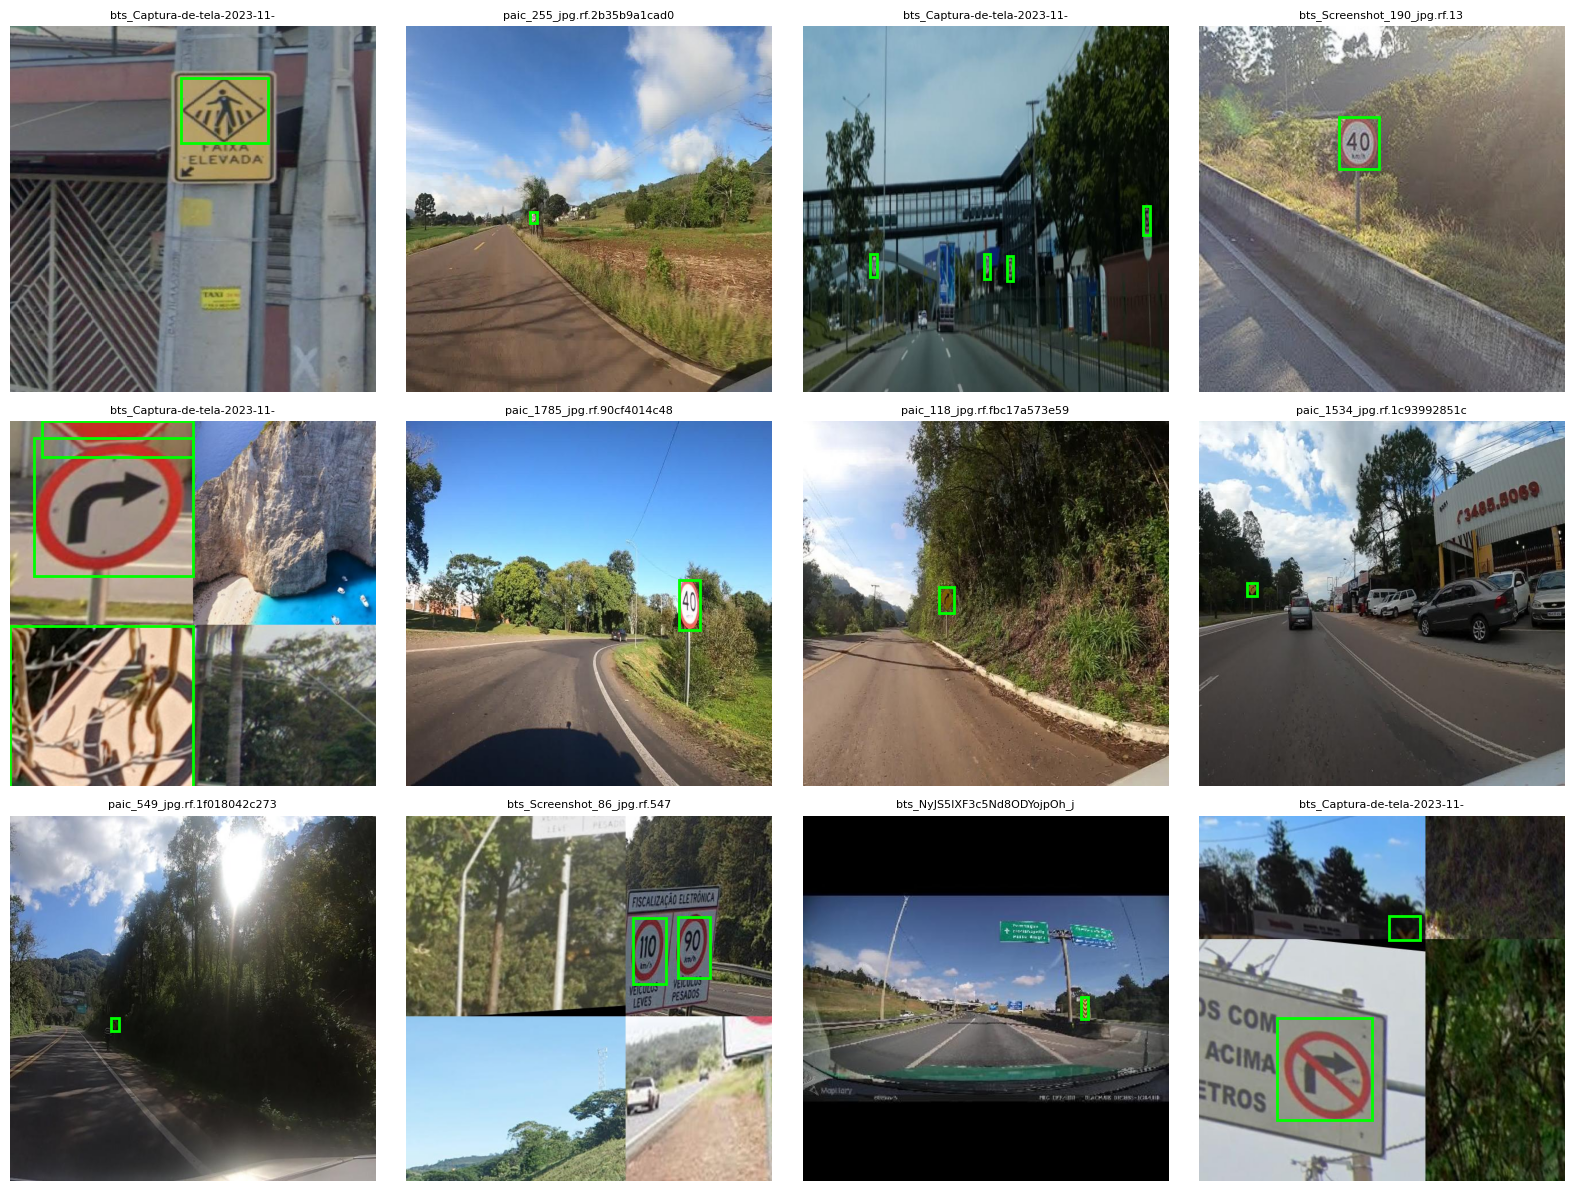

In [ ]:
import matplotlib.pyplot as plt, matplotlib.patches as patches

def mostrar_amostra(raiz: Path, split="train", n=12, seed=1):
    imgs = sorted((raiz / split / "images").iterdir())
    escolha = random.Random(seed).sample(imgs, min(n, len(imgs)))
    cols = 4; linhas = (len(escolha) + cols - 1) // cols
    fig, axs = plt.subplots(linhas, cols, figsize=(16, 4 * linhas))
    for ax, im in zip(np.ravel(axs), escolha):
        img = Image.open(im).convert("RGB"); W, H = img.size
        ax.imshow(img); ax.set_title(im.name[:28], fontsize=8); ax.axis("off")
        for c, x, y, w, h in ler_labels(raiz / split / "labels" / f"{im.stem}.txt") or []:
            ax.add_patch(patches.Rectangle(((x - w / 2) * W, (y - h / 2) * H), w * W, h * H, fill=False, color="lime", lw=2))
    for ax in np.ravel(axs)[len(escolha):]: ax.axis("off")
    plt.tight_layout(); plt.show()

if TREINAR:
    mostrar_amostra(DS_FINAL)

## 4. Treino *(Colab, GPU T4)*

Fine-tuning a partir do **`yolo26n.pt`** oficial (pré-treinado no COCO), com uma classe: `placa`.

- `fliplr=0.0`: segue a decisão do projeto (espelhar inverte setas e textos de placas).
- `hsv_v` e `hsv_s` maiores: o dataset tem pouca noite e chuva, então o treino varia mais o brilho e a saturação.
- Resultados em `SAIDA/detector_v1/` no Drive. Se o Colab desconectar, rode tudo de novo: com `RETOMAR=True` o treino continua do `last.pt`.
- Na T4, conte com ~1 a 2 min por época para ~8 mil imagens.

In [ ]:
from ultralytics import YOLO

PASTA_TREINO = Path(SAIDA) / MODEL_VERSION
ULTIMO = PASTA_TREINO / "weights" / "last.pt"
MELHOR = PASTA_TREINO / "weights" / "best.pt"

def treino_concluido(ckpt: Path) -> bool:
    """O Ultralytics marca epoch = -1 no last.pt quando o treino termina."""
    try:
        return torch.load(ckpt, map_location="cpu", weights_only=False).get("epoch", 0) == -1
    except Exception:
        return False

if TREINAR:
    if ULTIMO.exists() and treino_concluido(ULTIMO) and MELHOR.exists():
        print("Treino já concluído em", PASTA_TREINO, "- pulando. Apague a pasta para treinar de novo.")
    elif RETOMAR and ULTIMO.exists():
        print("Retomando treino de", ULTIMO)
        YOLO(str(ULTIMO)).train(resume=True)
    else:
        modelo = YOLO(PESOS_BASE)          # baixa o peso oficial YOLO26
        modelo.train(
            data=str(DATA_YAML),
            epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=BATCH, workers=WORKERS,
            device=DEVICE, seed=SEED,
            project=str(SAIDA), name=MODEL_VERSION, exist_ok=True,
            fliplr=0.0,
            hsv_h=0.015, hsv_s=0.7, hsv_v=0.5,
            degrees=0.0, translate=0.1, scale=0.5, mosaic=1.0, close_mosaic=10,
            plots=True,
        )
    print("Melhor peso:", MELHOR)

Retomando treino de /content/drive/MyDrive/DetectorPlacas/treinos/detector_v1/weights/last.pt
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=49, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/trabalho/data_placas.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive

## 5. Avaliação no split de teste *(Colab)*

In [ ]:
import csv, datetime, json

if TREINAR:
    m = YOLO(str(MELHOR)).val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=16, conf=0.001, iou=0.6,
                              device=DEVICE, project=str(SAIDA), name=f"{MODEL_VERSION}_teste", exist_ok=True)
    metricas = {"mAP50": round(float(m.box.map50), 4), "mAP50_95": round(float(m.box.map), 4),
                "precisao": round(float(m.box.mp), 4), "recall": round(float(m.box.mr), 4)}
    print(json.dumps(metricas, indent=2))

    # Registro para a planilha de experimentos
    REGISTRO = Path(SAIDA) / "experimentos.csv"
    novo = not REGISTRO.exists()
    with REGISTRO.open("a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if novo:
            w.writerow(["data", "model_version", "pesos_base", "imgsz", "epochs", "refazer_split",
                        "imagens_treino", "imagens_val", "imagens_teste", "mAP50", "mAP50_95", "precisao", "recall"])
        w.writerow([datetime.datetime.now().isoformat(timespec="minutes"), MODEL_VERSION, PESOS_BASE, IMGSZ, EPOCHS,
                    REFAZER_SPLIT, resumo_final["train"]["imagens"], resumo_final["valid"]["imagens"],
                    resumo_final["test"]["imagens"], *metricas.values()])
    print("Registrado em", REGISTRO)

> **Atenção:** este teste ainda usa o mesmo tipo de imagem do treino (Roboflow). O desempenho real precisa ser medido em
> **frames de Londrina** anotados, separados por condição (dia, pôr do sol, noite, chuva).

## 6. Exportar o modelo *(Colab)*

In [ ]:
if TREINAR:
    PESOS_MODELO.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(MELHOR, PESOS_MODELO)
    info = {
        "model_version": MODEL_VERSION, "pesos": PESOS_MODELO.name, "pesos_base": PESOS_BASE,
        "classes": CLASSES, "imgsz": IMGSZ, "conf": CONF, "iou": IOU,
        "ultralytics": ultralytics.__version__, "treinado_em": datetime.date.today().isoformat(),
        "metricas_teste": metricas,
        "contrato_bbox": "pixels do frame original; x1,y1 = canto superior esquerdo; x2,y2 = canto inferior direito",
    }
    (PESOS_MODELO.parent / f"{MODEL_VERSION}_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False))
    print("Pesos exportados:", PESOS_MODELO)
    print("Baixe a pasta", PESOS_MODELO.parent, "do Drive para DetectorPlacas/treinos/modelos/ no seu PC.")

## 7. Detector no formato do projeto *(PC ou Colab)*

`DetectorPlacas.detectar()` é a função reutilizável: recebe um frame (BGR do OpenCV), o número do frame, o tempo e o id do vídeo,
e devolve a lista de detecções no contrato.

`processar_video()` lê o vídeo **frame a frame**, desenha as caixas e salva os frames exatamente como a API exige:
`000001.jpg`, `000002.jpg`, … sem buracos e todos `.jpg`. Também salva `deteccoes.json`.

In [ ]:
import re, json, shutil, cv2
import numpy as np
from ultralytics import YOLO

class DetectorPlacas:
    def __init__(self, pesos, model_version=MODEL_VERSION, conf=CONF, iou=IOU, imgsz=IMGSZ, device=DEVICE):
        pesos = Path(pesos)
        if not pesos.exists():
            raise FileNotFoundError(f"Modelo não encontrado: {pesos}. Treine no Colab e copie o detector_v1.pt para cá.")
        self.modelo = YOLO(str(pesos))
        self.model_version, self.conf, self.iou, self.imgsz, self.device = model_version, conf, iou, imgsz, device
        self.nomes = self.modelo.names
        if list(self.nomes.values()) != CLASSES:
            raise ValueError(f"O modelo tem as classes {self.nomes}, mas o projeto espera {CLASSES}. Use o detector_v1.pt treinado neste notebook.")

    def detectar(self, frame_bgr, frame_id, timestamp, video_id):
        r = self.modelo.predict(frame_bgr, conf=self.conf, iou=self.iou, imgsz=self.imgsz,
                                device=self.device, verbose=False)[0]
        h, w = frame_bgr.shape[:2]
        saida = []
        for (x1, y1, x2, y2), c, k in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist()):
            saida.append({
                "video_id": str(video_id),
                "frame_id": int(frame_id),
                "timestamp": round(float(timestamp), 3),
                "class": self.nomes[int(k)],
                "confidence": round(float(c), 4),
                "bbox": {"x1": max(0, int(round(x1))), "y1": max(0, int(round(y1))),
                         "x2": min(w, int(round(x2))), "y2": min(h, int(round(y2)))},
                "model_version": self.model_version,
            })
        return saida

def desenhar(frame, deteccoes):
    for d in deteccoes:
        b = d["bbox"]
        cv2.rectangle(frame, (b["x1"], b["y1"]), (b["x2"], b["y2"]), (0, 255, 0), 2)
        cv2.putText(frame, f'{d["class"]} {d["confidence"]:.2f}', (b["x1"], max(12, b["y1"] - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1, cv2.LINE_AA)
    return frame

def validar_frames_api(pasta: Path, esperado=None):
    """Mesmas regras de verificar_frames() em backend/api/api.py."""
    arquivos = sorted(pasta.iterdir())
    if not arquivos: raise ValueError("Nenhum frame gerado.")
    nums, exts = [], set()
    for a in arquivos:
        if not re.fullmatch(r"\d{6}\.(jpg|png)", a.name): raise ValueError(f"Nome de frame inválido: {a.name}")
        nums.append(int(a.stem)); exts.add(a.suffix)
    nums.sort()
    if len(exts) != 1 or nums[0] not in (0, 1): raise ValueError("Frames devem iniciar em 0 ou 1 e ter a mesma extensão.")
    if nums != list(range(nums[0], nums[0] + len(nums))): raise ValueError("Frames duplicados ou faltando.")
    if esperado is not None and len(nums) != esperado: raise ValueError(f"Esperados {esperado}, gerados {len(nums)}.")
    return len(nums)

def processar_video(video, video_id, pasta_saida: Path, detector: DetectorPlacas, qualidade_jpg=90, mostrar_a_cada=100):
    pasta_saida = Path(pasta_saida)
    pasta_frames = pasta_saida / "frames"
    if pasta_frames.exists(): shutil.rmtree(pasta_frames)
    pasta_frames.mkdir(parents=True)
    cap = cv2.VideoCapture(str(video))
    if not cap.isOpened(): raise IOError(f"Não foi possível abrir {video}")
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    total_previsto = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    todas, n = [], 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        n += 1                                   # frames numerados a partir de 1, como a API aceita
        dets = detector.detectar(frame, frame_id=n, timestamp=(n - 1) / fps, video_id=video_id)
        todas.extend(dets)
        if not cv2.imwrite(str(pasta_frames / f"{n:06d}.jpg"), desenhar(frame, dets),
                           [cv2.IMWRITE_JPEG_QUALITY, qualidade_jpg]):
            raise IOError(f"Falha ao salvar o frame {n}")
        if mostrar_a_cada and n % mostrar_a_cada == 0:
            print(f"  {n}/{total_previsto} frames")
    cap.release()
    validar_frames_api(pasta_frames, n)
    resultado = {"video_id": str(video_id), "model_version": detector.model_version, "fps": fps,
                 "total_frames": n, "total_deteccoes": len(todas), "detections": todas}
    (pasta_saida / "deteccoes.json").write_text(json.dumps(resultado, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"{n} frames | {len(todas)} detecções | frames em {pasta_frames}")
    return resultado

detector = DetectorPlacas(PESOS_MODELO)
print("Modelo carregado:", PESOS_MODELO, "| classes:", detector.nomes)

Teste rápido em imagens (do split de teste no Colab; no PC, de qualquer pasta de frames):

In [ ]:
import matplotlib.pyplot as plt

PASTA_IMAGENS_TESTE = (TRABALHO / "placas_final" / "test" / "images") if TREINAR else Path(os.environ.get("PASTA_IMAGENS_TESTE", ""))
if PASTA_IMAGENS_TESTE.is_dir():
    amostra = sorted(p for p in PASTA_IMAGENS_TESTE.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})[:4]
    fig, axs = plt.subplots(1, len(amostra), figsize=(5 * len(amostra), 5))
    for ax, im in zip(np.atleast_1d(axs), amostra):
        frame = cv2.imread(str(im))
        dets = detector.detectar(frame, frame_id=0, timestamp=0, video_id="amostra")
        ax.imshow(cv2.cvtColor(desenhar(frame, dets), cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(f"{len(dets)} placa(s)")
    plt.show()
    print(json.dumps(dets[:2], indent=2, ensure_ascii=False))
else:
    print("Defina PASTA_IMAGENS_TESTE para ver exemplos.")

## 8. Enviar para a API do João *(PC)*

Antes, deixe a API rodando num terminal, na pasta `Integrative-Project-1/backend/api`:

```
pip install -r requirements.txt
python api.py
```

| Passo | Rota da API | O que o notebook faz |
|---|---|---|
| 1 | `POST /videos` (campo `video`) | envia o vídeo e recebe `job_id` e `original_fps` |
| 2 | — | roda o detector em todos os frames, com `video_id = job_id` |
| 3 | `POST /videos/<job_id>/frames` (campo `frames`) | envia os frames rotulados em lotes de até 200 MB (limite da API: 500 MB) |
| 4 | `POST /videos/<job_id>/finalize?expected_frames=N` | pede a montagem do vídeo |
| 5 | `GET /videos/<job_id>/status` | espera `done` ou `error` |
| 6 | `GET /videos/<job_id>/result` | baixa o `resultado.mp4` |

A API ainda não tem rota para as detecções; elas ficam em `deteccoes_<job_id>.json`, ao lado do vídeo final.

In [ ]:
import time, requests

def api_disponivel(api_url):
    try:
        requests.get(f"{api_url.rstrip('/')}/videos/teste/status", timeout=5)   # 404 = API no ar
        return True
    except requests.RequestException:
        return False

def enviar_para_api(api_url, video, detector, pasta_trabalho: Path, lote_mb=200, timeout_montagem=1800):
    api_url = api_url.rstrip("/")
    # 1) cria o job
    with open(video, "rb") as fh:
        r = requests.post(f"{api_url}/videos", files={"video": (Path(video).name, fh)}, timeout=600)
    if r.status_code != 201:
        raise RuntimeError(f"POST /videos falhou: {r.status_code} {r.text}")
    job = r.json(); job_id = job["job_id"]
    print("Job criado:", job)

    # 2) processa com video_id = job_id
    pasta_job = Path(pasta_trabalho) / job_id
    res = processar_video(video, job_id, pasta_job, detector)

    # 3) envia frames em lotes
    frames = sorted((pasta_job / "frames").iterdir())
    def enviar(lote):
        arquivos = [("frames", (p.name, open(p, "rb"), "image/jpeg")) for p in lote]
        try:
            resp = requests.post(f"{api_url}/videos/{job_id}/frames", files=arquivos, timeout=600)
        finally:
            for _, (_, fh, _) in arquivos: fh.close()
        if resp.status_code != 200:
            raise RuntimeError(f"Falha ao enviar frames: {resp.status_code} {resp.text}")
        return resp.json()["received"]
    lote, tamanho, enviados = [], 0, 0
    for p in frames:
        tam = p.stat().st_size
        if lote and tamanho + tam > lote_mb * 1024 * 1024:
            enviados += enviar(lote); lote, tamanho = [], 0
        lote.append(p); tamanho += tam
    if lote: enviados += enviar(lote)
    print("Frames enviados:", enviados)

    # 4) finaliza (a API usa o FPS do vídeo original)
    r = requests.post(f"{api_url}/videos/{job_id}/finalize", params={"expected_frames": len(frames)}, timeout=60)
    if r.status_code != 202:
        raise RuntimeError(f"Falha no finalize: {r.status_code} {r.text}")

    # 5) espera a montagem
    inicio = time.time()
    while True:
        st = requests.get(f"{api_url}/videos/{job_id}/status", timeout=30).json()
        if st["status"] == "done": break
        if st["status"] == "error": raise RuntimeError(f"A API retornou erro: {st['error']}")
        if time.time() - inicio > timeout_montagem: raise TimeoutError("A montagem demorou demais.")
        time.sleep(2)

    # 6) baixa o resultado e guarda as detecções
    destino = pasta_job / "resultado.mp4"
    with requests.get(f"{api_url}/videos/{job_id}/result", stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(destino, "wb") as f:
            for parte in r.iter_content(1 << 20): f.write(parte)
    shutil.copy2(pasta_job / "deteccoes.json", pasta_job / f"deteccoes_{job_id}.json")
    print("Vídeo final:", destino)
    print("Detecções:", pasta_job / f"deteccoes_{job_id}.json")
    return job_id, destino, res

if not VIDEO_TESTE:
    print("Defina VIDEO_TESTE na seção 1 (caminho de um vídeo) para rodar esta etapa.")
elif EM_COLAB:
    print("No Colab a API do PC não é acessível. Processando só localmente (sem API)...")
    res = processar_video(VIDEO_TESTE, Path(VIDEO_TESTE).stem, TRABALHO / "video_local", detector)
elif not api_disponivel(API_URL):
    print(f"A API não respondeu em {API_URL}. Inicie com: python backend/api/api.py")
else:
    job_id, video_final, res = enviar_para_api(API_URL, VIDEO_TESTE, detector, TRABALHO / "jobs")
    print(json.dumps(res["detections"][:3], indent=2, ensure_ascii=False))